# DDX6 knock-down (KD) and over-expression (OE): stress-granule (SG) quantification
Refactored version of `All_transfections_3rep.ipynb`. **Pipeline order is unchanged**:
KD read CSVs → KD index SG counts/areas → KD TAC → OE read CSVs → OE index → flatten / remove zeros / px→µm² → TAC → datasets → statistics → plots.

What changed: the ~480 hand-written `read_csv` lines and the copy-pasted per-condition blocks are replaced by one file manifest per experiment, one loader, one `SGData` class and one plotting helper.
Spots where the original code contained a copy-paste error are tagged `# FIX n` in the code and listed in the table at the bottom of this notebook.

In [1]:
import os
import warnings
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scikit_posthocs as sp
import scipy.stats as stats
import seaborn as sb
from statsmodels.stats.multicomp import pairwise_tukeyhsd

warnings.simplefilter("ignore", FutureWarning)   # seaborn deprecation notes (palette / errwidth); plots unaffected

os.chdir("/Users/gemechu/Library/CloudStorage/OneDrive-JohnsHopkins/Data/Cell_experiments/Xincheng_cell_data")

PX_TO_UM2 = 0.0352908 ** 2   # pixel size is 0.0352908 µm  ->  pixel² to µm²


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Users/gemechu/opt/miniconda3/lib/python3.9/runpy.py", line 197, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Users/gemechu/opt/miniconda3/lib/python3.9/runpy.py", line 87, in _run_code
    exec(code, run_globals)
  File "/Users/gemechu/opt/miniconda3/lib/python3.9/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/gemechu/opt/miniconda3/lib/python3.9/site-packages/traitlets/config/application.py", line 1075, in launch_instance
 

AttributeError: _ARRAY_API not found

## Helpers

In [2]:
def files(folder, stem, fovs, prophiler=(), sg_names=None):
    """File manifest for one condition (3 replicates).

    folder    path template with {rep} and (optionally) {cp} placeholders
    stem      file-name stem before the FOV number (one string, or one per replicate)
    fovs      list of FOV numbers to analyse, one list per replicate
    prophiler replicates whose CellProfiler folder is spelled 'cell_prophiler_files'
    sg_names  {rep: {fov: file name}} for SG files that do not follow the stem pattern
    CellProfiler writes <stem><FOV>Cytoplasm.csv (one row per cell) and <stem><FOV>SGs.csv (one row per SG).
    """
    stems = [stem] * 3 if isinstance(stem, str) else stem
    return {rep: dict(folder=folder.format(rep=rep, cp="cell_prophiler_files" if rep in prophiler else "cell_profiler_files"),
                      stem=stems[rep - 1], fovs=fovs[rep - 1], sg_names=(sg_names or {}).get(rep, {}))
            for rep in (1, 2, 3)}


def read_condition(spec):
    """Read the Cytoplasm and SG tables of every FOV: {rep: {'cyto': [df, ...], 'sg': [df, ...]}}"""
    tables = {}
    for rep, s in spec.items():
        cyto_files = [f"{s['stem']}{fov}Cytoplasm.csv" for fov in s["fovs"]]
        sg_files = [s["sg_names"].get(fov, f"{s['stem']}{fov}SGs.csv") for fov in s["fovs"]]
        tables[rep] = dict(cyto=[pd.read_csv(f"{s['folder']}/{name}") for name in cyto_files],
                           sg=[pd.read_csv(f"{s['folder']}/{name}") for name in sg_files])
    return tables


@dataclass
class SGData:
    """SG measurements of one transfection condition; one list entry per replicate."""
    count_rep: list   # SG count of every cell, zeros kept
    area_rep: list    # area of every SG in µm²

    @classmethod
    def from_tables(cls, tables):
        reps = sorted(tables)
        count_rep = [np.concatenate([t["Children_SGs_Count"].to_numpy() for t in tables[r]["cyto"]]) for r in reps]
        area_rep = [PX_TO_UM2 * np.concatenate([t["AreaShape_Area"].to_numpy() for t in tables[r]["sg"]]) for r in reps]
        return cls(count_rep, area_rep)

    # flatten across FOVs / replicates; f_ = cells without any SG removed
    @property
    def f_count_rep(self): return [c[c != 0] for c in self.count_rep]
    @property
    def count(self):       return np.concatenate(self.count_rep)
    @property
    def f_count(self):     return np.concatenate(self.f_count_rep)
    @property
    def area(self):        return np.concatenate(self.area_rep)
    # per-replicate means
    @property
    def f_count_means(self): return [c.mean() for c in self.f_count_rep]
    @property
    def area_means(self):    return [a.mean() for a in self.area_rep]
    @property
    def TAC(self):           # total area covered = mean SG count (cells with SGs) x mean SG area, per replicate
        return [c * a for c, a in zip(self.f_count_means, self.area_means)]


def summarise(conditions):
    """One-line-per-condition checkpoint: number of cells / SGs and TAC of each replicate."""
    return pd.DataFrame.from_dict(
        {k: dict(cells=len(d.count), cells_with_SGs=len(d.f_count), SGs=len(d.area),
                 TAC_r1=d.TAC[0], TAC_r2=d.TAC[1], TAC_r3=d.TAC[2]) for k, d in conditions.items()},
        orient="index").round(3)

# KD

## READ IN CSV FILES

In [3]:
KD_FILES = {   # concentrations in nM
    "ctrl": files("DDX6_KD/DDX6_KD_rep{rep}/control/{cp}/analysis", "DDX6_siRNA_ctrl_AS",
                  [[1, 2, 4, 5], [1, 3, 5, 6], [1, 2, 3, 4, 6]]),
    "5":    files("DDX6_KD/DDX6_KD_rep{rep}/5nm/{cp}/analysis",     # FIX 1: rep1 SG files were read from the rep2 folder
                  ["DDX6_siRNA_5nm_AS", "DDX6_siRNA_5nM2_AS", "DDX6_siRNA_5nM3_AS"],
                  [[1, 2, 4, 5, 6], [1, 2, 4, 5, 6], [1, 2, 3, 4, 5]]),
    "7.5":  files("gemechu_DDX6_KD_more_concentrations/rep{rep}/75nm/{cp}/analysis", "DDX6_siRNA_75nM_AS",
                  [[2, 3, 4, 5], [1, 2, 5], [3, 4, 5]], prophiler=(1,)),
    "10":   files("DDX6_KD/DDX6_KD_rep{rep}/10nm/{cp}/analysis",
                  ["DDX6_siRNA_10nm_AS", "DDX6_siRNA_10nM2_AS", "DDX6_siRNA_10nM3_AS"],
                  [[1, 2, 3, 4, 5, 6], [1, 2, 3, 4, 5], [1, 3, 4, 5, 6]]),
    "15":   files("gemechu_DDX6_KD_more_concentrations/rep{rep}/15nm/{cp}/analysis", "DDX6_siRNA_15nM_AS",
                  [[1, 2, 4, 5], [2, 4, 5], [2, 3, 4, 5]], prophiler=(1,)),
    "20":   files("DDX6_KD/DDX6_KD_rep{rep}/20nm/{cp}/analysis",   # FIX 2: rep2 Cytoplasm files were all AS1; FIX 4: pooled area skipped rep3 FOV 7
                  ["DDX6_siRNA_20nm_AS", "DDX6_siRNA_20nM2_AS", "DDX6_siRNA_20nM3_AS"],
                  [[1, 2, 3, 4, 5, 6], [1, 2, 3, 4, 5, 6], [1, 2, 3, 4, 5, 6, 7]],
                  sg_names={2: {f: f"DDX6_siRNA_20nm2_AS{f}SGs.csv" for f in range(2, 7)}}),   # spelling as in the original
    "25":   files("gemechu_DDX6_KD_more_concentrations/rep{rep}/25nm/{cp}/analysis", "DDX6_siRNA_25nM_AS",
                  [[1, 2, 3, 4, 5, 6], [1, 3, 4, 5], [1, 4, 5]], prophiler=(1,)),
    "30":   files("gemechu_DDX6_KD_more_concentrations/rep{rep}/30nm/{cp}/analysis", "DDX6_siRNA_30nM_AS",
                  [[3, 4, 6], [3, 4, 5], [2, 3, 4, 5]], prophiler=(1,)),
}

kd_tables = {cond: read_condition(spec) for cond, spec in KD_FILES.items()}

## INDEX SG COUNTS AND AREA VALUES

In [5]:
KD = {cond: SGData.from_tables(tables) for cond, tables in kd_tables.items()}
summarise(KD)

,cells,cells_with_SGs,SGs,TAC_r1,TAC_r2,TAC_r3
ctrl,175,75,134,3.972,3.080,3.371
5,210,84,154,2.977,3.756,2.838
7.5,143,65,121,2.664,4.181,3.307
10,221,88,158,2.880,3.418,3.499
15,164,51,84,2.113,3.938,2.303
20,263,111,181,1.926,2.433,2.985
25,170,56,96,2.733,2.950,2.825
30,171,51,91,3.188,2.492,2.966


### FOR ANALYSIS OF SEPARATE REPLICATES

#### calculate means for each replicate

In [6]:
rep_means_KD = pd.concat({"count": pd.DataFrame({k: d.f_count_means for k, d in KD.items()}).T,
                          "area":  pd.DataFrame({k: d.area_means for k, d in KD.items()}).T})
rep_means_KD.columns = ["rep1", "rep2", "rep3"]
rep_means_KD.round(3)

rep1   rep2   rep3
count ctrl  2.056  1.609  1.765
      5     1.958  2.038  1.588
      7.5   1.800  2.043  1.727
      10    1.481  2.000  1.867
      15    1.500  1.889  1.524
      20    1.433  1.618  1.766
      25    1.645  1.714  1.909
      30    1.500  1.471  2.125
area  ctrl  1.932  1.914  1.910
      5     1.520  1.842  1.787
      7.5   1.480  2.046  1.914
      10    1.944  1.709  1.874
      15    1.409  2.085  1.511
      20    1.344  1.504  1.690
      25    1.661  1.721  1.480
      30    2.125  1.694  1.396

# OE

## READ IN CSV FILES

In [7]:
OE_FILES = {   # µg DDX6-GFP
    "ctrl": files("DDX6_OE/DDX6_overexpress_rep{rep}/GFP_cont/{cp}/analysis",
                  ["DDX6_ctrl_1_AS", "DDX6_ctrl_AS", "DDX6_ctrl_AS"],
                  [[2, 3, 4, 5], [1, 2, 3, 4], [1, 3, 4, 5, 6, 7]]),
    "0.1":  files("DDX6_OE/DDX6_overexpress_rep{rep}/0_1ug_DDX6-GFP/{cp}/analysis", "DDX6_0_1_AS",
                  [[1, 2, 3], [1, 2, 3], [1, 3, 4, 5]]),                       # FIX 3: rep1 FOV 2 SG file was read from FOV 1
    "0.4":  files("DDX6_OE/DDX6_overexpress_rep{rep}/0_4ug_DDX6-GFP/{cp}/analysis", "DDX6_0_4_AS",
                  [[1, 3, 4, 5], [1, 3, 4, 5, 6, 7], [2, 3, 4, 5]]),
    "0.7":  files("DDX6_OE/DDX6_overexpress_rep{rep}/0_7ug_DDX6-GFP/{cp}/analysis", "DDX6_0_7_AS",
                  [[3, 4, 6, 7], [2, 3, 4, 5, 7, 8], [2, 3, 4, 5, 6]]),       # FIX 4: pooled list counted rep2 FOV 4 twice
    "1.0":  files("DDX6_OE/DDX6_overexpress_rep{rep}/1_0ug_DDX6-GFP/{cp}/analysis", "DDX6_1_0_AS",
                  [[3, 4, 6, 7, 8, 9], [1, 3, 4, 5, 6], [1, 2, 3, 5]]),
    "1.3":  files("gemechu_DDX6_OE_more_concentrations/rep{rep}/1.3ug/cell_prophiler_files/analysis", "DDX6_1_3_AS",
                  [[2, 3, 4, 6], [1, 2, 3, 5], [1, 5]]),
    "1.5":  files("gemechu_DDX6_OE_more_concentrations/rep{rep}/1.5ug/cell_prophiler_files/analysis", "DDX6_1_5_AS",
                  [[2, 3, 6], [1, 2, 5, 6], [1, 2, 3, 4, 5, 6]]),             # FIX 4: rep3 mean listed FOV 4 twice and skipped FOV 3
    "1.8":  files("gemechu_DDX6_OE_more_concentrations/rep{rep}/1.8ug/cell_prophiler_files/analysis", "DDX6_1_8_AS",
                  [[2, 3, 4, 5, 6], [2, 3, 4, 5], [1, 2, 3, 4, 5, 6]]),
    "2.0":  files("DDX6_OE/DDX6_overexpress_rep{rep}/2_0ug_DDX6-GFP/{cp}/analysis", "DDX6_2_0_AS",
                  [[1, 3, 5, 6, 7], [1, 2, 3, 4, 5, 6, 7], [1, 2, 4, 5, 6]],   # FIX 4: pooled list counted rep1 FOV 5 twice
                  prophiler=(1,)),
}

oe_tables = {cond: read_condition(spec) for cond, spec in OE_FILES.items()}

## Index SG count and area

Flatten FOVs → remove zeroes from the counts → convert area from pixels to µm² all happen inside `SGData.from_tables` and its properties.

In [8]:
OE = {cond: SGData.from_tables(tables) for cond, tables in oe_tables.items()}
summarise(OE)

,cells,cells_with_SGs,SGs,TAC_r1,TAC_r2,TAC_r3
ctrl,134,73,168,6.806,4.281,4.615
0.1,116,61,127,3.953,2.674,4.140
0.4,112,74,202,4.983,4.887,4.334
0.7,122,78,212,6.144,4.473,4.544
1.0,175,79,170,3.491,4.647,3.881
1.3,90,41,99,7.449,4.597,3.635
1.5,125,64,149,5.383,3.105,5.007
1.8,149,83,181,3.328,2.974,5.548
2.0,170,88,248,4.440,4.612,3.268


## Replicate means

In [9]:
rep_means_OE = pd.concat({"count": pd.DataFrame({k: d.f_count_means for k, d in OE.items()}).T,
                          "area":  pd.DataFrame({k: d.area_means for k, d in OE.items()}).T})
rep_means_OE.columns = ["rep1", "rep2", "rep3"]
rep_means_OE.round(3)

rep1   rep2   rep3
count ctrl  2.765  1.957  2.303
      0.1   2.375  1.880  2.100
      0.4   2.600  2.816  2.688
      0.7   3.700  2.367  2.737
      1.0   1.686  2.591  2.455
      1.3   3.500  2.000  1.875
      1.5   2.455  1.955  2.548
      1.8   2.000  1.720  2.733
      2.0   2.464  3.382  2.462
area  ctrl  2.462  2.188  2.004
      0.1   1.664  1.422  1.971
      0.4   1.916  1.736  1.612
      0.7   1.661  1.890  1.660
      1.0   2.071  1.794  1.581
      1.3   2.128  2.298  1.938
      1.5   2.193  1.588  1.965
      1.8   1.664  1.729  2.030
      2.0   1.802  1.364  1.328

## Total area covered quantification

`SGData.TAC` = mean SG count per SG-containing cell × mean SG area (µm²), one value per replicate.

In [10]:
pd.DataFrame({**{f"KD {k}": d.TAC for k, d in KD.items()}, **{f"OE {k}": d.TAC for k, d in OE.items()}}).T.round(3)

,0,1,2
KD ctrl,3.972,3.080,3.371
KD 5,2.977,3.756,2.838
KD 7.5,2.664,4.181,3.307
KD 10,2.880,3.418,3.499
KD 15,2.113,3.938,2.303
KD 20,1.926,2.433,2.985
KD 25,2.733,2.950,2.825
KD 30,3.188,2.492,2.966
OE ctrl,6.806,4.281,4.615
OE 0.1,3.953,2.674,4.140


## Make datasets for statistical analysis and plotting

In [11]:
# condition order and labels used from here on
KD_ORDER = ["30", "20", "15", "10", "7.5", "5", "ctrl"]                      # descending siRNA, control last
OE_ORDER = ["ctrl", "0.1", "0.4", "0.7", "1.0", "1.3", "1.5", "1.8", "2.0"]
KD_DS = dict(zip(KD_ORDER, ["30 nM", "20 nM", "15 nM", "10 nM", "7.5 nM", "5 nM", "si_ctrl"]))
OE_DS = dict(zip(OE_ORDER, ["CTRL", "0.1 ug", "0.4 ug", "0.7 ug", "1.0 ug", "1.3 ug", "1.5 ug", "1.8 ug", "2 ug"]))
OE_NO_1_3 = [k for k in OE_ORDER if k != "1.3"]                               # 1.3 ug is not part of the df_OE_* tables (as in the original)


def long_df(groups):
    """{label: values} -> long table with columns Group / Value"""
    return pd.DataFrame([(g, v) for g, vals in groups.items() for v in vals], columns=["Group", "Value"])


def n_per_group(df):
    return df.groupby("Group", sort=False).size().to_dict()


df_KD_area  = long_df({KD_DS[k]: KD[k].area    for k in KD_ORDER})
df_KD_count = long_df({KD_DS[k]: KD[k].f_count for k in KD_ORDER})
df_KD_TAC   = long_df({KD_DS[k]: KD[k].TAC     for k in KD_ORDER})                       # FIX 7: 7.5 nM was missing, so labels were shifted
df_OE_area  = long_df({OE_DS[k]: OE[k].area    for k in OE_NO_1_3})
df_OE_count = long_df({OE_DS[k]: OE[k].f_count for k in OE_NO_1_3})
df_OE_TAC   = long_df({OE_DS[k]: (KD["ctrl"].TAC if k == "ctrl" else OE[k].TAC) for k in OE_NO_1_3})   # CTRL = siRNA ctrl TAC, as in the original

# all 14 conditions that appear in the combined plots (KD <= 20 nM, then OE); used for the TAC statistics
ALL_KEYS = [("KD", k) for k in ["20", "15", "10", "7.5", "5", "ctrl"]] + [("OE", k) for k in OE_ORDER[1:]]
ALL_DS = ["20 nM", "15 nM", "10 nM", "7.5 nM", "5 nM", "si_ctrl", "0.1 ug", "0.4 ug", "0.7 ug", "1.0 ug", "1.3 ug", "1.5 ug", "1.8 ug", "2 ug"]
pick = lambda exp, k: (KD if exp == "KD" else OE)[k]
df_all_TAC = long_df({lbl: pick(*key).TAC for lbl, key in zip(ALL_DS, ALL_KEYS)})         # FIX 7

for name, df in dict(KD_area=df_KD_area, KD_count=df_KD_count, KD_TAC=df_KD_TAC,
                     OE_area=df_OE_area, OE_count=df_OE_count, OE_TAC=df_OE_TAC, all_TAC=df_all_TAC).items():
    print(f"{name:9s}", n_per_group(df))

KD_area   {'30 nM': 91, '20 nM': 181, '15 nM': 84, '10 nM': 158, '7.5 nM': 121, '5 nM': 154, 'si_ctrl': 134}
KD_count  {'30 nM': 51, '20 nM': 111, '15 nM': 51, '10 nM': 88, '7.5 nM': 65, '5 nM': 84, 'si_ctrl': 75}
KD_TAC    {'30 nM': 3, '20 nM': 3, '15 nM': 3, '10 nM': 3, '7.5 nM': 3, '5 nM': 3, 'si_ctrl': 3}
OE_area   {'CTRL': 168, '0.1 ug': 127, '0.4 ug': 202, '0.7 ug': 212, '1.0 ug': 170, '1.5 ug': 149, '1.8 ug': 181, '2 ug': 248}
OE_count  {'CTRL': 73, '0.1 ug': 61, '0.4 ug': 74, '0.7 ug': 78, '1.0 ug': 79, '1.5 ug': 64, '1.8 ug': 83, '2 ug': 88}
OE_TAC    {'CTRL': 3, '0.1 ug': 3, '0.4 ug': 3, '0.7 ug': 3, '1.0 ug': 3, '1.5 ug': 3, '1.8 ug': 3, '2 ug': 3}
all_TAC   {'20 nM': 3, '15 nM': 3, '10 nM': 3, '7.5 nM': 3, '5 nM': 3, 'si_ctrl': 3, '0.1 ug': 3, '0.4 ug': 3, '0.7 ug': 3, '1.0 ug': 3, '1.3 ug': 3, '1.5 ug': 3, '1.8 ug': 3, '2 ug': 3}


### KD statistics

In [18]:
def kruskal(*groups):
    stat, p = stats.kruskal(*groups)
    print(f"Kruskal-Wallis statistic: {stat}, P-value: {p}")

KD_TESTED = ["ctrl", "5", "7.5", "10", "15", "20"]       # 25 / 30 nM are not part of these tests

# exploratory pairwise comparisons between experiments (SG area)
print(stats.ttest_ind(KD["20"].area, OE["1.3"].area))
print(stats.mannwhitneyu(KD["20"].area, OE["1.3"].area))
print(stats.mannwhitneyu(KD["20"].area, OE["0.4"].area))
print(stats.mannwhitneyu(KD["20"].area, OE["0.7"].area))

print("KD area");  kruskal(*[KD[k].area    for k in KD_TESTED])
print("KD count"); kruskal(*[KD[k].f_count for k in KD_TESTED])
print("KD TAC");   kruskal(*[KD[k].TAC     for k in KD_TESTED])

TtestResult(statistic=np.float64(-3.3451552241801688), pvalue=np.float64(0.0009354957838171738), df=np.float64(278.0))
MannwhitneyuResult(statistic=np.float64(7681.5), pvalue=np.float64(0.04859122442286498))
MannwhitneyuResult(statistic=np.float64(16795.5), pvalue=np.float64(0.16978512418792058))
MannwhitneyuResult(statistic=np.float64(18784.0), pvalue=np.float64(0.7205661700150225))
KD area
Kruskal-Wallis statistic: 2.6900418833891213, P-value: 0.7476410608984475
KD count
Kruskal-Wallis statistic: 3.541793709839765, P-value: 0.6170733599262785
KD TAC
Kruskal-Wallis statistic: 5.1169590643274745, P-value: 0.4017738727714715


In [21]:
def kruskal(*groups):
    stat, p = stats.kruskal(*groups)
    print(f"Kruskal-Wallis statistic: {stat}, P-value: {p}")

KD_TESTED = ["ctrl", "5", "7.5", "10", "15", "20"]       # 25 / 30 nM are not part of these tests

# exploratory pairwise comparisons between experiments (SG area)
print(stats.ttest_ind(KD["20"].count, OE["1.3"].count))
print(stats.mannwhitneyu(KD["20"].count, OE["1.3"].count))
print(stats.mannwhitneyu(KD["20"].count, OE["0.4"].count))
print(stats.mannwhitneyu(KD["20"].count, OE["0.7"].count))

print("KD area");  kruskal(*[KD[k].area    for k in KD_TESTED])
print("KD count"); kruskal(*[KD[k].f_count for k in KD_TESTED])
print("KD TAC");   kruskal(*[KD[k].TAC     for k in KD_TESTED])

TtestResult(statistic=np.float64(-2.7742759031032036), pvalue=np.float64(0.005828360641227903), df=np.float64(351.0))
MannwhitneyuResult(statistic=np.float64(10826.0), pvalue=np.float64(0.1778060095595153))
MannwhitneyuResult(statistic=np.float64(9710.5), pvalue=np.float64(1.6197873013475427e-08))
MannwhitneyuResult(statistic=np.float64(10743.0), pvalue=np.float64(1.6674598938916722e-08))
KD area
Kruskal-Wallis statistic: 2.6900418833891213, P-value: 0.7476410608984475
KD count
Kruskal-Wallis statistic: 3.541793709839765, P-value: 0.6170733599262785
KD TAC
Kruskal-Wallis statistic: 5.1169590643274745, P-value: 0.4017738727714715


### OE statistics

In [24]:
OE_TESTED = ["0.1", "0.4", "0.7", "1.0", "1.3", "1.5", "1.8", "2.0"]
# NOTE (unchanged from the original): the reference group here is the *siRNA* control (KD["ctrl"]), not the GFP control (OE["ctrl"])

print("OE area");  kruskal(KD["ctrl"].area,    *[OE[k].area    for k in OE_TESTED])
print("OE count"); kruskal(KD["ctrl"].f_count, *[OE[k].f_count for k in OE_TESTED])

dunn_count = sp.posthoc_dunn([KD["ctrl"].f_count] + [OE[k].f_count for k in OE_TESTED], p_adjust="bonferroni")   # FIX 9: call raised TypeError
print(dunn_count)

print("OE TAC (1.3 ug not included, as in the original)")
kruskal(KD["ctrl"].TAC, *[OE[k].TAC for k in OE_TESTED if k != "1.3"])

dunn_TAC = sp.posthoc_dunn(df_all_TAC, val_col="Value", group_col="Group", p_adjust="bonferroni")
print(dunn_TAC)

OE area
Kruskal-Wallis statistic: 16.952209608924605, P-value: 0.030610582144153724
OE count
Kruskal-Wallis statistic: 28.014002414492374, P-value: 0.00047159339637303896
          1         2         3         4         5    6    7         8  \
1  1.000000  1.000000  0.021768  0.002278  1.000000  1.0  1.0  1.000000   
2  1.000000  1.000000  1.000000  0.401443  1.000000  1.0  1.0  1.000000   
3  0.021768  1.000000  1.000000  1.000000  1.000000  1.0  1.0  1.000000   
4  0.002278  0.401443  1.000000  1.000000  0.389790  1.0  1.0  0.554644   
5  1.000000  1.000000  1.000000  0.389790  1.000000  1.0  1.0  1.000000   
6  1.000000  1.000000  1.000000  1.000000  1.000000  1.0  1.0  1.000000   
7  1.000000  1.000000  1.000000  1.000000  1.000000  1.0  1.0  1.000000   
8  1.000000  1.000000  1.000000  0.554644  1.000000  1.0  1.0  1.000000   
9  0.003344  0.578480  1.000000  1.000000  0.569101  1.0  1.0  0.807195   

          9  
1  0.003344  
2  0.578480  
3  1.000000  
4  1.000000  
5  0.569

In [25]:
print(stats.ttest_ind(OE["1.3"].TAC, KD["20"].TAC))

f_stat, p_value = stats.f_oneway(*[pick(*key).TAC for key in ALL_KEYS])
print(f"F-statistic: {f_stat}, p-value: {p_value}")

# FIX 9: the original passed a (14, 3) list of arrays to pairwise_tukeyhsd, which returned NaN p-values
tukey = pairwise_tukeyhsd(df_all_TAC["Value"], df_all_TAC["Group"])
print(tukey)

TtestResult(statistic=np.float64(2.3443046086065427), pvalue=np.float64(0.07900555861653333), df=np.float64(4.0))
F-statistic: 2.3434871272927986, p-value: 0.028781550420601487
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1  group2 meandiff p-adj   lower  upper  reject
----------------------------------------------------
0.1 ug  0.4 ug   1.1458 0.9576   -1.66 3.9516  False
0.1 ug  0.7 ug   1.4651 0.8042 -1.3407 4.2709  False
0.1 ug  1.0 ug   0.4179    1.0  -2.388 3.2237  False
0.1 ug  1.3 ug   1.6381 0.6722 -1.1677 4.4439  False
0.1 ug  1.5 ug   0.9096 0.9935 -1.8962 3.7154  False
0.1 ug  1.8 ug    0.361    1.0 -2.4448 3.1668  False
0.1 ug   10 nM  -0.3233    1.0 -3.1291 2.4825  False
0.1 ug   15 nM  -0.8039  0.998 -3.6097 2.0019  False
0.1 ug    2 ug   0.5184    1.0 -2.2874 3.3242  False
0.1 ug   20 nM   -1.141 0.9589 -3.9468 1.6648  False
0.1 ug    5 nM  -0.3984    1.0 -3.2042 2.4074  False
0.1 ug  7.5 nM  -0.2051    1.0 -3.0109 2.6007  False
0.1 ug si_ctrl  -0.1144    1

## Plot Data

In [26]:
KD_LABELS = ["30 nM", "20 nM", "15 nM", "10 nM", "7.5 nM", "5 nM", "siRNA CTRL"]          # FIX 8: the first plot cell labelled the 30 nM data '25 nM'
OE_LABELS = ["GFP CTRL", "0.1ug DDDX6", "0.4ug DDDX6", "0.7ug DDDX6", "1.0ug DDDX6", "1.3ug DDDX6",
             "1.5ug DDDX6", "1.8ug DDDX6", "2.0ug DDDX6"]
ALL_LABELS = KD_LABELS[1:] + OE_LABELS[1:]

KD6 = ["20", "15", "10", "7.5", "5", "ctrl"]     # KD conditions of the combined plots
OE8 = OE_ORDER[1:]                               # all OE doses without the GFP control

kd_of = lambda attr, keys: [getattr(KD[k], attr) for k in keys]
oe_of = lambda attr, keys: [getattr(OE[k], attr) for k in keys]
all_of = lambda attr: [getattr(pick(*key), attr) for key in ALL_KEYS]

_saved = set()

def finish_plot(ax, labels, ylabel, title, xlabel="transfection", ylim=None, save=None):
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    if ylim: ax.set_ylim(*ylim)
    if save:
        if save in _saved:
            print(f"note: {save} was already written in this session and is overwritten")
        _saved.add(save)
        ax.figure.savefig(save, format="pdf")
    plt.show()


def plot_groups(data, labels, kind, main_kw, strip_kw=None, strip_data=None, figsize=None, **finish_kw):
    """Box- or barplot of `data` (list of arrays) with optional strip overlay (`strip_data` defaults to `data`)."""
    fig, ax = plt.subplots(figsize=figsize)
    getattr(sb, f"{kind}plot")(data=data, ax=ax, **main_kw)
    if strip_kw is not None:
        sb.stripplot(data=data if strip_data is None else strip_data, ax=ax, **strip_kw)
    finish_plot(ax, labels, **finish_kw)

### KD plots

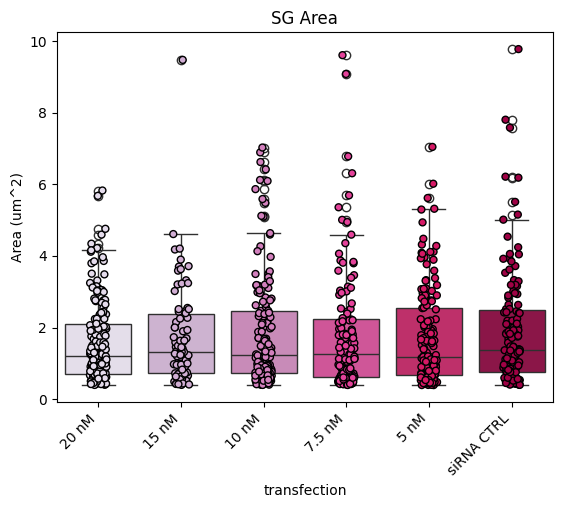

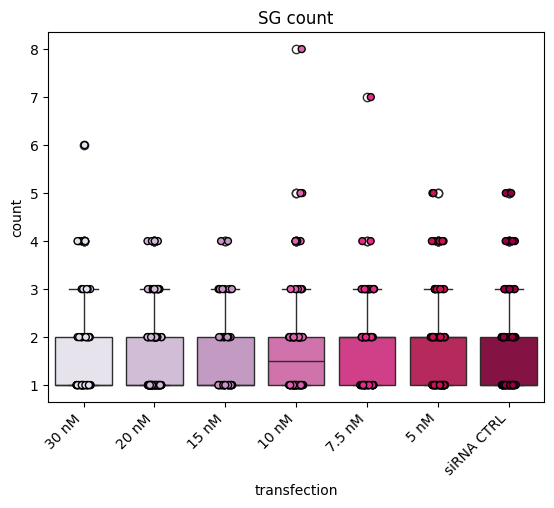

In [27]:
plot_groups(kd_of("area", KD6), KD_LABELS[1:], "box", dict(palette="PuRd"),
            dict(palette="PuRd", size=5, edgecolor="black", linewidth=1, color="black", jitter=True),
            ylabel="Area (um^2)", title="SG Area", save="FUS_DDX6_KD_area_box.pdf")

plot_groups(kd_of("f_count", KD_ORDER), KD_LABELS, "box", dict(hue=None, palette="PuRd"),
            dict(hue=None, palette="PuRd", size=5, edgecolor="black", linewidth=1, color="black", jitter=True),
            ylabel="count", title="SG count", save="FUS_DDX6_KD_count_box.pdf")

### OE Plots

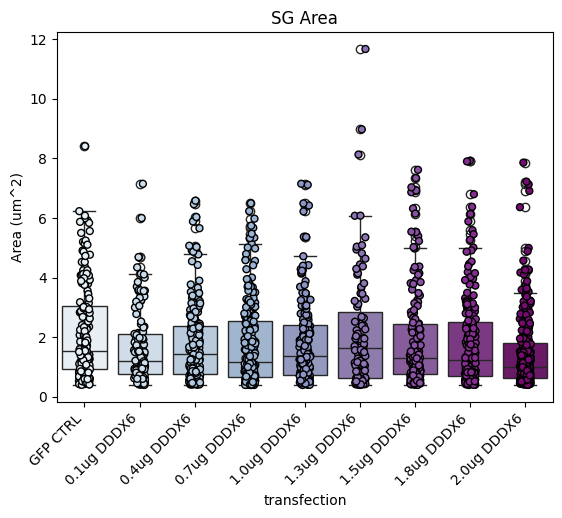

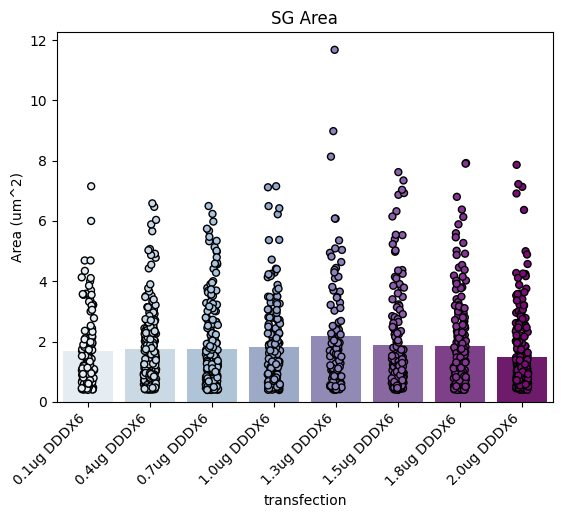

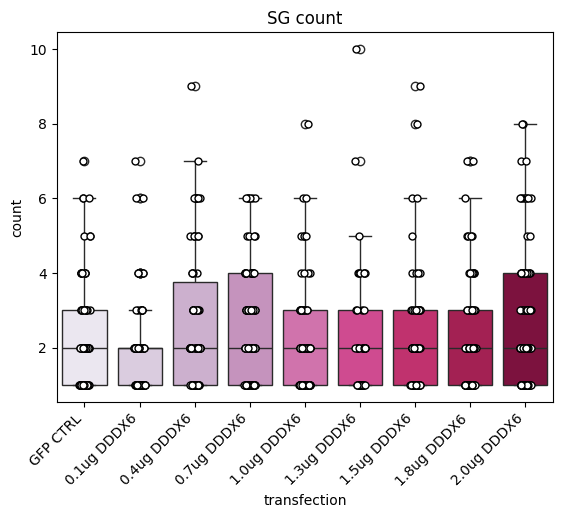

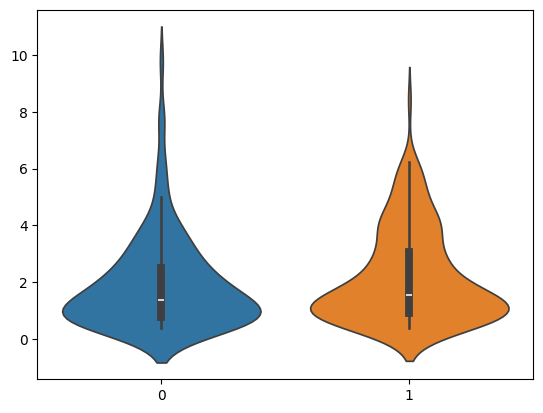

note: FUS_DDX6_OE_count_box.pdf was already written in this session and is overwritten


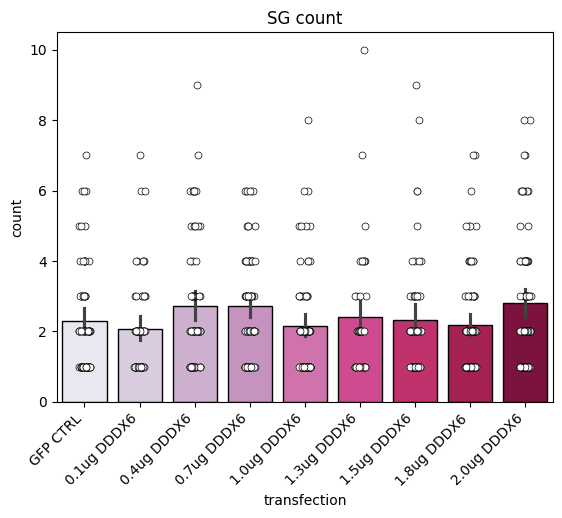

In [28]:
oe_strip_black = dict(palette="BuPu", size=5, edgecolor="black", linewidth=1, color="black", jitter=True, dodge=False)
plot_groups(oe_of("area", OE_ORDER[:1] + OE8), OE_LABELS, "box", dict(palette="BuPu"), oe_strip_black,
            ylabel="Area (um^2)", title="SG Area", save="FUS_DDX6_OE_area_box.pdf")
plot_groups(oe_of("area", OE8), OE_LABELS[1:], "bar", dict(palette="BuPu"), oe_strip_black,
            ylabel="Area (um^2)", title="SG Area", save="FUS_DDX6_OE_area_bar.pdf")

# FIX 8: the original used the unfiltered 1.3 ug count (SG_count_1_3, zeros included) in the next two plots
oe_count_white = dict(size=5, edgecolor="black", linewidth=1, color="white", jitter=True)
plot_groups(oe_of("f_count", OE_ORDER), OE_LABELS, "box", dict(palette="PuRd"), oe_count_white,
            ylabel="count", title="SG count", save="FUS_DDX6_OE_count_box.pdf")

sb.violinplot(data=[KD["ctrl"].area, OE["ctrl"].area])     # quick look: siRNA control vs GFP control area
plt.show()

plot_groups(oe_of("f_count", OE_ORDER), OE_LABELS, "bar", dict(edgecolor="black", palette="PuRd"),
            dict(size=5, edgecolor="black", linewidth=0.5, color="white", jitter=True),
            ylabel="count", title="SG count", save="FUS_DDX6_OE_count_box.pdf")

## ALL

note: FUS_DDX6_all_area_rep_bar_final.pdf was already written in this session and is overwritten


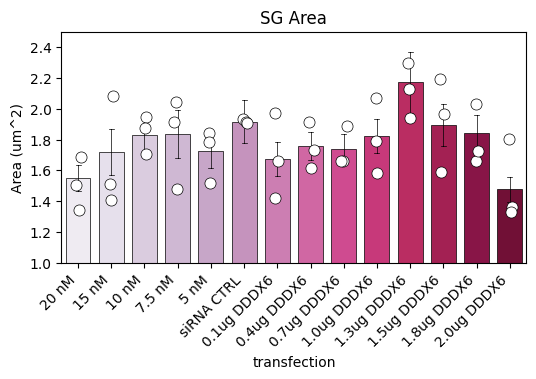

note: FUS_DDX6_all_count_rep_bar_final.pdf was already written in this session and is overwritten


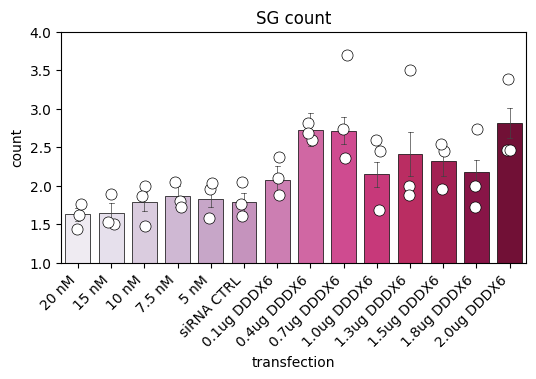

In [31]:
strip8 = dict(size=8, edgecolor="black", linewidth=0.5, color="white", jitter=True, dodge=True)

plot_groups(all_of("area"), ALL_LABELS, "bar",
            dict(width=0.75, errorbar="se", errwidth=0.5, edgecolor="black", capsize=0.15, errcolor="black", linewidth=0.5, palette="PuRd"),
            strip8, strip_data=all_of("area_means"), figsize=(6, 3), ylim=(1, 2.5),
            ylabel="Area (um^2)", title="SG Area", save="FUS_DDX6_all_area_rep_bar_final.pdf")

plot_groups(all_of("f_count"), ALL_LABELS, "bar",
            dict(width=0.75, errorbar="se", errwidth=0.5, edgecolor="black", capsize=0.15, linewidth=0.5, palette="PuRd"),
            strip8, strip_data=all_of("f_count_means"), figsize=(6, 3), ylim=(1, 4),
            ylabel="count", title="SG count", save="FUS_DDX6_all_count_rep_bar_final.pdf")


## REPLICATES

### KD plots

[[0.7001502181782511, 0.7836379578765184, 0.8807555068729528], [0.7340910716509603, 1.0864450298347954, 0.787602020163435], [1.0128780205540042, 0.8905116940671375, 0.9767681260664753], [0.7711561807696828, 1.0660583895038704, 0.9975812621657363], [0.7922494467753206, 0.9600791182034641, 0.9311346721702384], [1.0070199188418723, 0.9975655679987276, 0.9954145131594]]


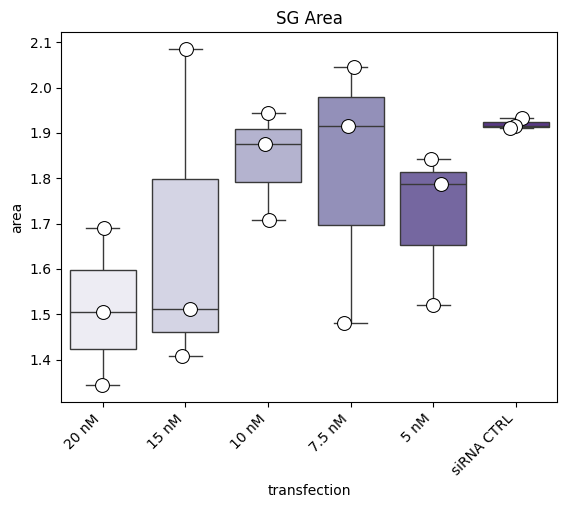

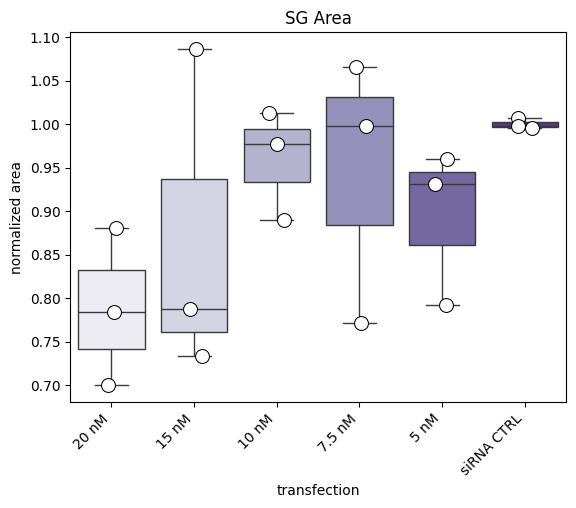

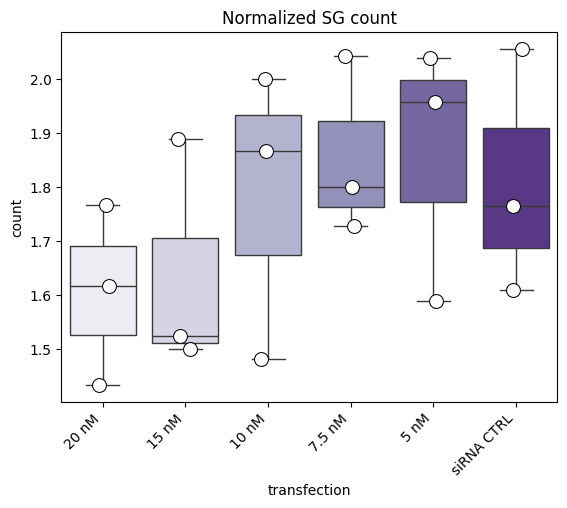

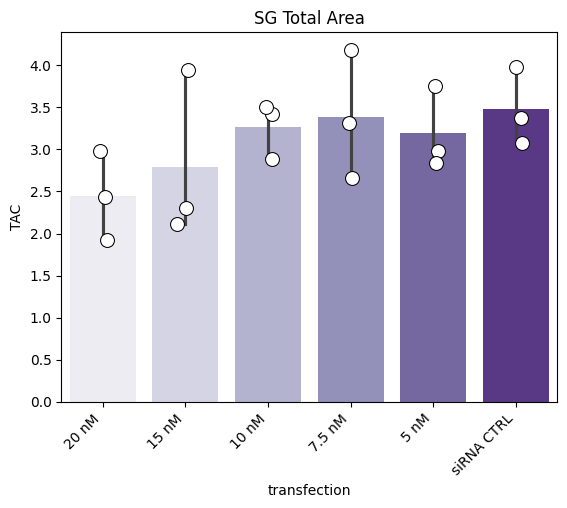

In [32]:
area_means_KD = kd_of("area_means", KD6)
ctrl_area_mean = np.mean(KD["ctrl"].area_means)
n_area_means_KD = [np.array(m) / ctrl_area_mean for m in area_means_KD]          # FIX 10: replaces hard-coded pasted values
print([m.tolist() for m in n_area_means_KD])

rep_strip = dict(color="white", size=10, edgecolor="black", linewidth=0.75, jitter=True, dodge=True)
rep_box = dict(width=0.8, linewidth=1, palette="Purples")

plot_groups(area_means_KD, KD_LABELS[1:], "box", rep_box, rep_strip,
            ylabel="area", title="SG Area", save="FUS_DDX6_KD_area_rep_box.pdf")
plot_groups(n_area_means_KD, KD_LABELS[1:], "box", rep_box, rep_strip,
            ylabel="normalized area", title="SG Area", save="FUS_DDX6_KD_area_box_rep_norm.pdf")
plot_groups(kd_of("f_count_means", KD6), KD_LABELS[1:], "box", rep_box, rep_strip,
            ylabel="count", title="Normalized SG count", save="FUS_DDX6_KD_count_rep_box.pdf")
plot_groups(kd_of("TAC", KD6), KD_LABELS[1:], "bar", rep_box, rep_strip,
            ylabel="TAC", title="SG Total Area", save="FUS_DDX6_KD_TAC_rep_box.pdf")

### OE Plots

[[1.109930998476626, 0.9865580761887304, 0.9035109253346435], [0.7503337850652645, 0.641178777575861, 0.8887386277947865], [0.8639886555018854, 0.7825184873755567, 0.7269785060066049], [0.7486237431953808, 0.8520874691518129, 0.7486123615528559], [0.9337651282673165, 0.8086700943098031, 0.7128482899433658], [0.9595270244699782, 1.0362244808865173, 0.8739098290049617], [0.9887915759944342, 0.7161142429527457, 0.8857964514770399], [0.7501263910001584, 0.7794847580974309, 0.9150509319459856], [0.8123765567285087, 0.6148070338377065, 0.5986144060696713]]
[np.float64(0.11114433493725742), np.float64(0.09140859299569738), np.float64(0.09721395226624777), np.float64(0.10951133742366445), np.float64(0.1993728048826573), np.float64(0.13683932557062012), np.float64(0.11599985045056857), np.float64(0.08237033751081724)]


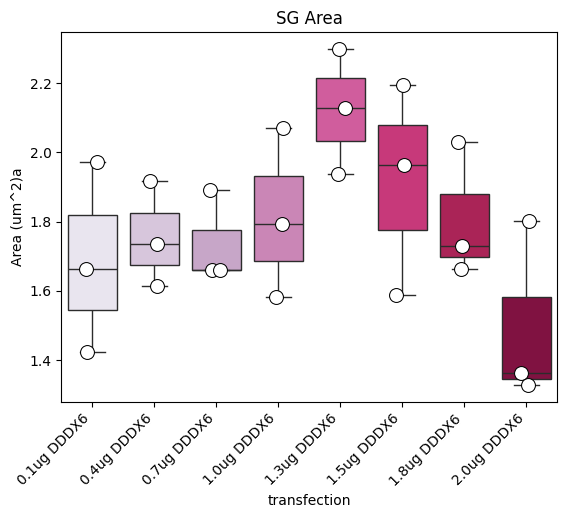

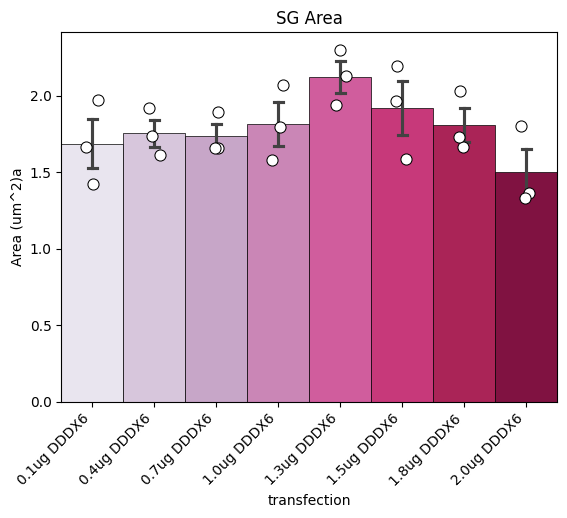

note: FUS_DDX6_OE_area_rep_bar.pdf was already written in this session and is overwritten


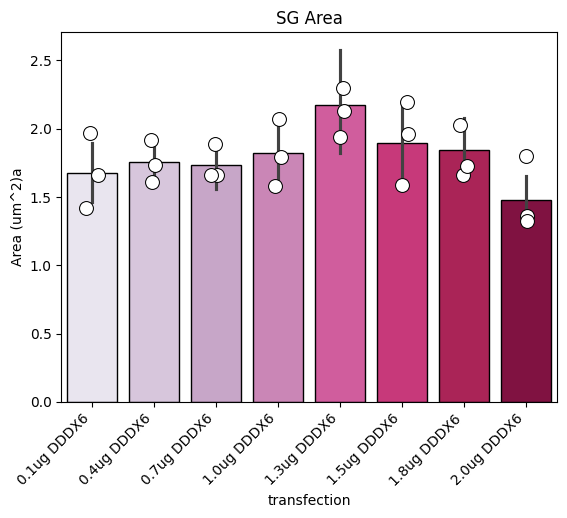

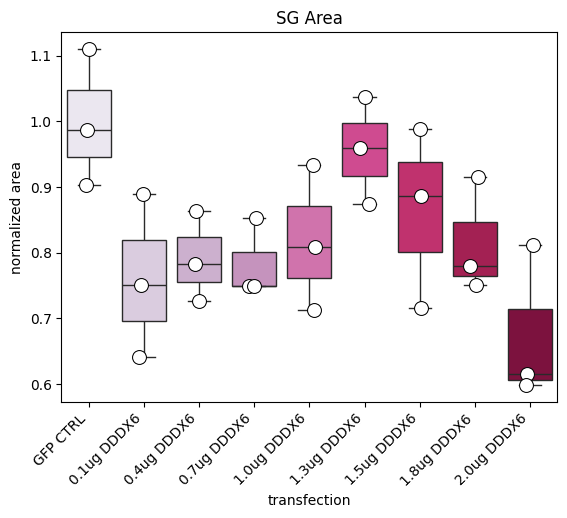

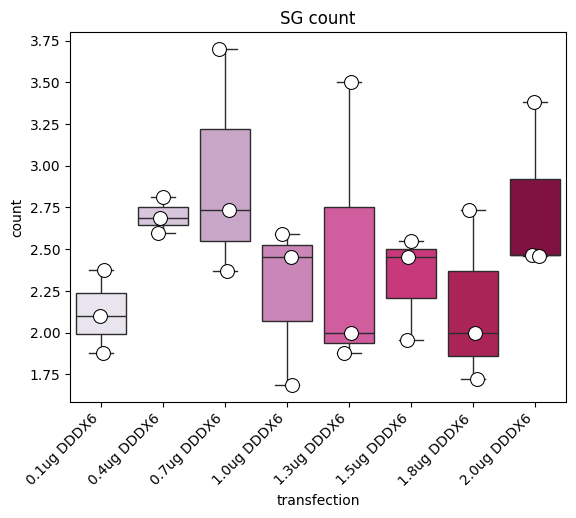

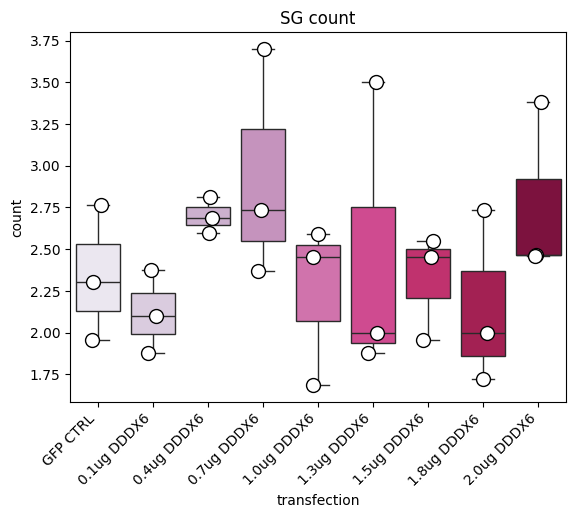

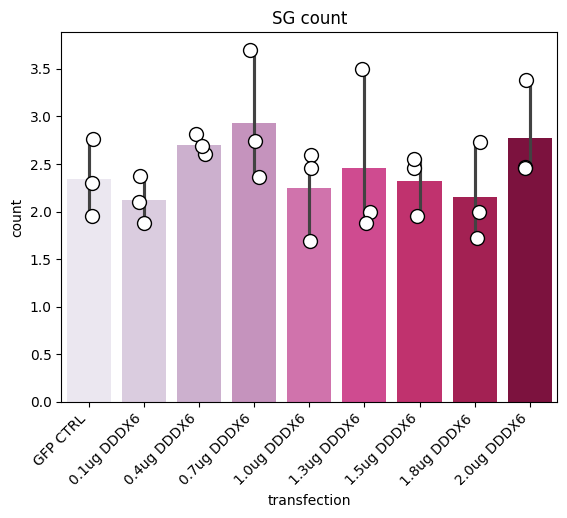

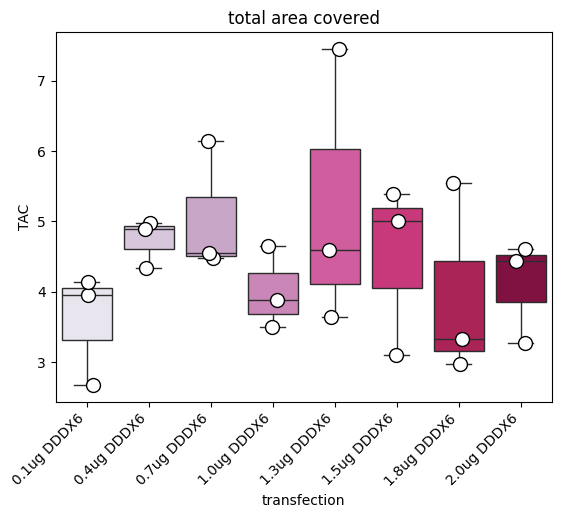

In [33]:
area_means_OE = oe_of("area_means", OE_ORDER)                                       # GFP control + 8 doses
ctrl_area_mean = np.mean(OE["ctrl"].area_means)
n_area_means_OE = [np.array(m) / ctrl_area_mean for m in area_means_OE]          # FIX 10: replaces hard-coded pasted values
print([m.tolist() for m in n_area_means_OE])

SEM_vals = [stats.sem(OE[k].area) for k in OE8]                                  # SEM of the pooled SG areas, per dose
print(SEM_vals)

box10 = dict(width=0.8, linewidth=1, palette="PuRd")
strip10 = dict(size=10, edgecolor="black", linewidth=0.75, color="white", jitter=True, dodge=True)

plot_groups(oe_of("area_means", OE8), OE_LABELS[1:], "box", box10, strip10,
            ylabel="Area (um^2)a", title="SG Area", save="FUS_DDX6_OE_area_rep_box.pdf")
plot_groups(oe_of("area_means", OE8), OE_LABELS[1:], "bar",
            dict(width=1, errorbar="se", edgecolor="black", capsize=0.15, linewidth=0.5, palette="PuRd"),
            dict(size=8, edgecolor="black", linewidth=0.75, color="white", jitter=True, dodge=True),
            ylabel="Area (um^2)a", title="SG Area", save="FUS_DDX6_OE_area_rep_bar.pdf")
plot_groups(oe_of("area", OE8), OE_LABELS[1:], "bar", dict(width=0.8, edgecolor="black", linewidth=1, palette="PuRd"),
            strip10, strip_data=oe_of("area_means", OE8),
            ylabel="Area (um^2)a", title="SG Area", save="FUS_DDX6_OE_area_rep_bar.pdf")
plot_groups(n_area_means_OE, OE_LABELS, "box", box10, strip10,
            ylabel="normalized area", title="SG Area", save="FUS_DDX6_OE_area_rep_box_norm.pdf")

plot_groups(oe_of("f_count_means", OE8), OE_LABELS[1:], "box", box10, strip10,
            ylabel="count", title="SG count", save="FUS_DDX6_OE_count_rep1_box.pdf")
plot_groups(oe_of("f_count_means", OE_ORDER), OE_LABELS, "box", box10,
            dict(size=10, edgecolor="black", linewidth=1, color="white", jitter=True, dodge=True),
            ylabel="count", title="SG count", save="FUS_DDX6_OE_count_rep_box.pdf")
plot_groups(oe_of("f_count_means", OE_ORDER), OE_LABELS, "bar", dict(palette="PuRd"),
            dict(size=10, edgecolor="black", linewidth=1, color="white", jitter=True, dodge=True),
            ylabel="count", title="SG count", save="FUS_DDX6_OE_count_rep_bar.pdf")
# FIX 8: the original listed TAC_1_5 before TAC_1_3 here (labels 1.3 / 1.5 swapped) and re-used the 'count' axis labels
plot_groups(oe_of("TAC", OE8), OE_LABELS[1:], "box", box10,
            dict(size=10, edgecolor="black", linewidth=1, color="white", jitter=True, dodge=True),
            ylabel="TAC", title="total area covered", save="FUS_DDX6_OE_TAC_rep_box.pdf")

### ALL TRANSFECTIONS

1.2533008990468315


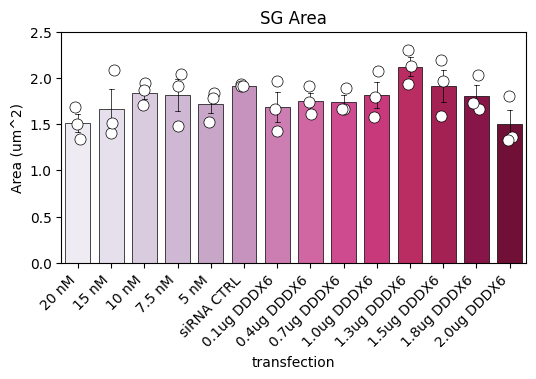

note: FUS_DDX6_all_count_rep_box.pdf was already written in this session and is overwritten


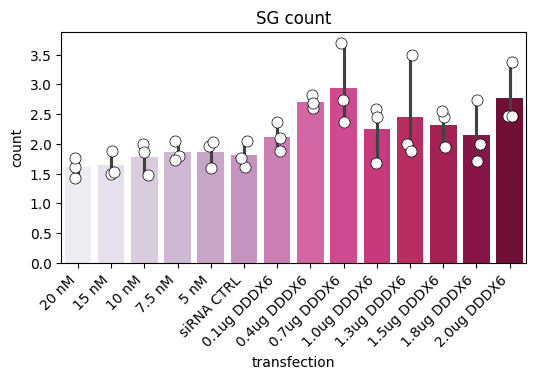

note: FUS_DDX6_all_count_rep_box.pdf was already written in this session and is overwritten


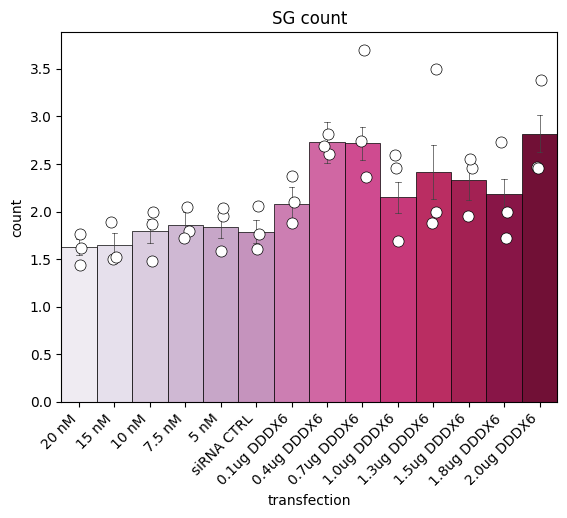

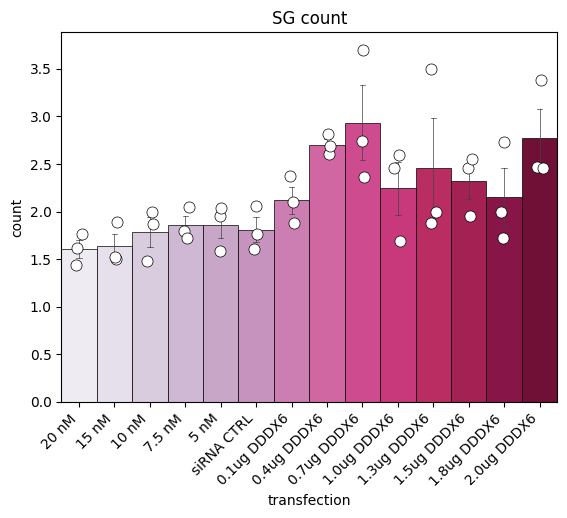

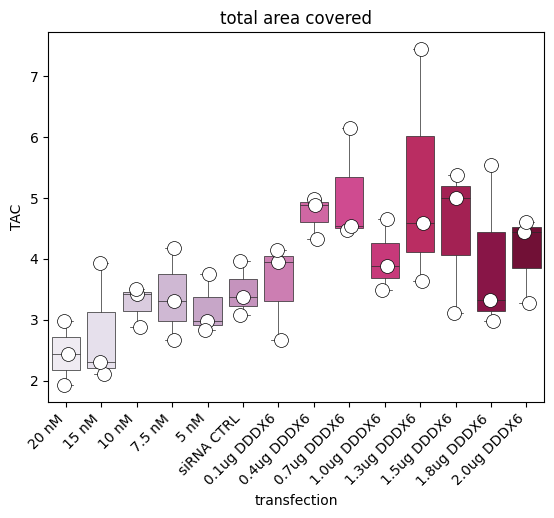

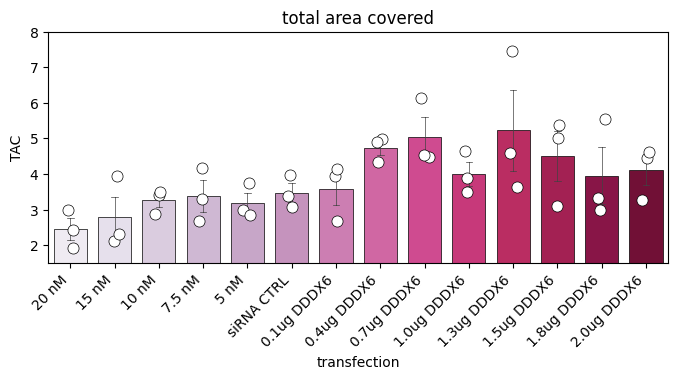

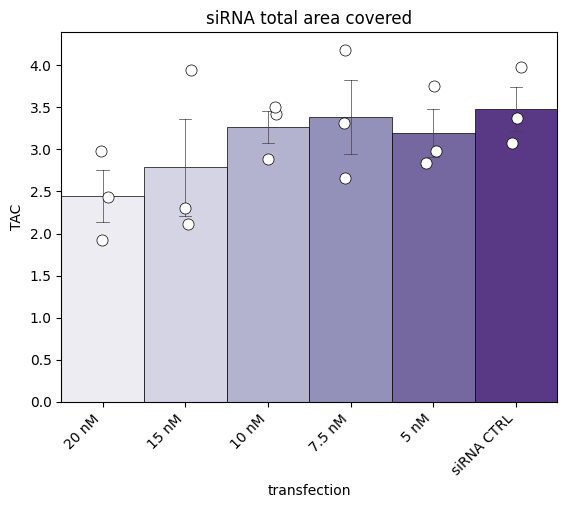

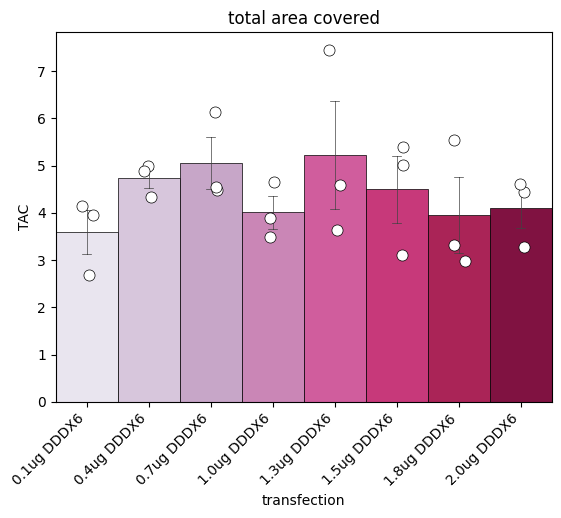

In [34]:
print(np.mean(OE["0.7"].f_count_means) / np.mean(OE["ctrl"].f_count_means))      # 0.7 ug vs GFP control: fold change of mean SG count

plot_groups(all_of("area_means"), ALL_LABELS, "bar",
            dict(width=0.75, errorbar="se", errwidth=0.5, edgecolor="black", capsize=0.15, errcolor="black", linewidth=0.5, palette="PuRd"),
            strip8, figsize=(6, 3), ylim=(0, 2.5),
            ylabel="Area (um^2)", title="SG Area", save="FUS_DDX6_all_area_rep_bar.pdf")

plot_groups(all_of("f_count_means"), ALL_LABELS, "bar", dict(linewidth=0.5, palette="PuRd"), strip8, figsize=(6, 3),
            ylabel="count", title="SG count", save="FUS_DDX6_all_count_rep_box.pdf")

plot_groups(all_of("f_count"), ALL_LABELS, "bar",       # FIX 8: first bar used the 25 nM replicate lists instead of the pooled 20 nM counts
            dict(width=1, errorbar="se", errwidth=0.5, edgecolor="black", capsize=0.15, linewidth=0.5, palette="PuRd"),
            strip8, strip_data=all_of("f_count_means"),
            ylabel="count", title="SG count", save="FUS_DDX6_all_count_rep_box.pdf")

plot_groups(all_of("f_count_means"), ALL_LABELS, "bar",
            dict(width=1, errwidth=0.5, edgecolor="black", errorbar="se", capsize=0.15, linewidth=0.5, palette="PuRd"),
            strip8, ylabel="count", title="SG count", save="FUS_DDX6_all_count_rep_bar.pdf")

plot_groups(all_of("TAC"), ALL_LABELS, "box", dict(linewidth=0.5, palette="PuRd"),
            dict(size=10, edgecolor="black", linewidth=0.5, color="white", jitter=True, dodge=True),
            ylabel="TAC", title="total area covered", save="FUS_DDX6_all_TAC_box.pdf")

plot_groups(all_of("TAC"), ALL_LABELS, "bar",
            dict(errorbar="se", width=0.75, errwidth=0.5, edgecolor="black", capsize=0.15, linewidth=0.5, palette="PuRd"),
            strip8, figsize=(8, 3), ylim=(1.5, 8),
            ylabel="TAC", title="total area covered", save="FUS_DDX6_all_TAC_bar.pdf")

plot_groups(kd_of("TAC", KD6), KD_LABELS[1:], "bar",
            dict(errorbar="se", width=1, errwidth=0.5, edgecolor="black", capsize=0.15, linewidth=0.5, palette="Purples"),
            strip8, ylabel="TAC", title="siRNA total area covered", save="FUS_DDX6_KD_TAC_bar.pdf")

plot_groups(oe_of("TAC", OE8), OE_LABELS[1:], "bar",
            dict(errorbar="se", width=1, errwidth=0.5, edgecolor="black", capsize=0.15, linewidth=0.5, palette="PuRd"),
            strip8, ylabel="TAC", title="total area covered", save="FUS_DDX6_OE_TAC_bar.pdf")

{'20 nM': 3, '15 nM': 3, '10 nM': 3, '7.5 nM': 3, '5 nM': 3, 'siRNA CTRL': 3, '0.1ug DDDX6': 3, '0.4ug DDDX6': 3, '0.7ug DDDX6': 3, '1.0ug DDDX6': 3, '1.3ug DDDX6': 3, '1.5ug DDDX6': 3, '1.8ug DDDX6': 3, '2.0ug DDDX6': 3}
note: FUS_DDX6_all_TAC_bar.pdf was already written in this session and is overwritten


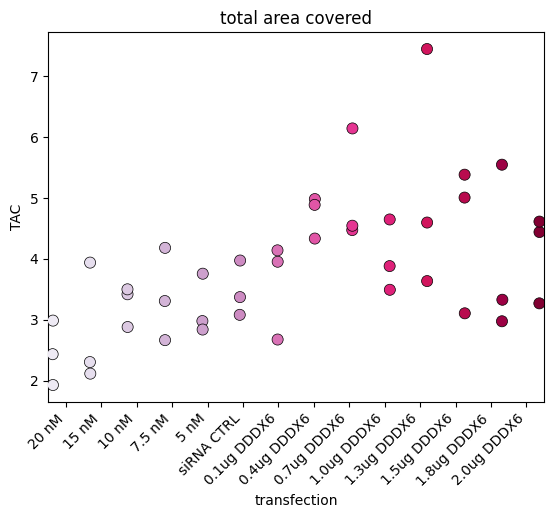

note: FUS_DDX6_all_TAC_bar.pdf was already written in this session and is overwritten


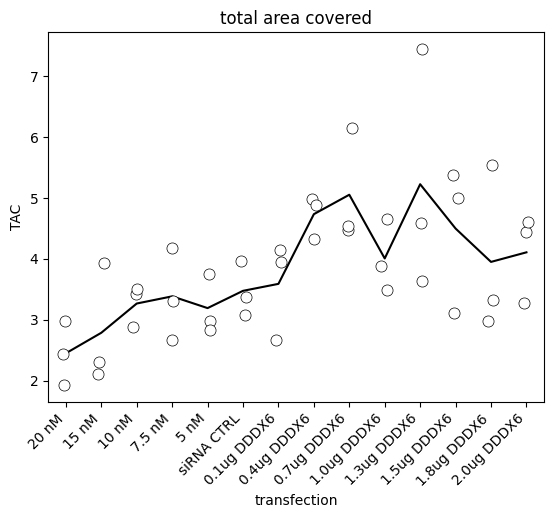

In [35]:
df_TAC_rep1 = long_df(dict(zip(ALL_LABELS, all_of("TAC"))))
print(n_per_group(df_TAC_rep1))

fig, ax1 = plt.subplots()
sb.stripplot(x="Group", y="Value", data=df_TAC_rep1, size=8, edgecolor="black", linewidth=0.5,
             ax=ax1, palette="PuRd", jitter=True, dodge=True)
finish_plot(ax1, ALL_LABELS, ylabel="TAC", title="total area covered", save="FUS_DDX6_all_TAC_bar.pdf")   # FIX 8: labels were set on the previous figure's axes

fig, ax1 = plt.subplots()
sb.lineplot(x="Group", y="Value", data=df_TAC_rep1, color="black", errorbar=None, ax=ax1)
sb.stripplot(x="Group", y="Value", data=df_TAC_rep1, size=8, edgecolor="black", linewidth=0.5,
             ax=ax1, color="white", jitter=True, dodge=True)
finish_plot(ax1, ALL_LABELS, ylabel="TAC", title="total area covered", save="FUS_DDX6_all_TAC_bar.pdf")